# Single strategy analysis

Notebook to analyze a single strategy from `results/runs/`. Set `STRATEGY` and `RUN_NUMBERS` in the configuration cell below — the three run numbers are read positionally as the top-10, top-50 and top-100 backtests. The notebook

- summarises the run configuration (optimizer, parameter grid, windows, universe files),
- tabulates the backtest metrics for every universe size the strategy was run on, next to the 1/N reference,
- plots cumulative out-of-sample returns for the three universe sizes, with the 1/N portfolio for reference.

Metrics taken from `metrics.json`:

- Expected shortfall at 80% confidence level (ES80)
- Expected shortfall at 95% confidence level (ES95)
- Annualized volatility (Vol)
- Sharpe ratio (SR)
- Soritno ratio (SOR)
- Maximum drawdown (MD)
- Expected shortfall ratio (ESR)
- Average asset turnover (AAT)
- Average currency turnover (ACT)

## Configuration

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

RUNS_DIR = Path("runs")
FIGURES_DIR = Path("figures")

# ---- what to analyse -------------------------------------------------------
STRATEGY = "reg_es_asset_full"                     # any sub-directory of results/runs
RUN_NUMBERS = [5, 7, 6]                       # run_N to use, positionally = UNIVERSE_SIZES

REFERENCE_STRATEGY = "equal_weight_optimizer"
REFERENCE_RUN_NUMBERS = [1, 2, 3]             # same convention for the 1/N reference

# Positional meaning of the run numbers above: first: top-10, second: top-50,
# third: top-100. Change if a strategy was backtested on other universe sizes.
UNIVERSE_SIZES = [10, 50, 100]

LOG_Y = False        
SAVE_FIGURES = False  
TRADING_DAYS = 252
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
REF_COLOR = "#6f6e6a"
GRID_KW = dict(alpha=0.25, linewidth=0.6)

In [2]:
def load_runs(strategy: str, run_numbers: list[int], universe_sizes: list[int] = None) -> dict[int, dict]:
    """Load `run_<n>` of `strategy` for each n in `run_numbers`.

    The i-th run number is taken to be the backtest on the i-th universe size
    (by default 10 / 50 / 100).  If that disagrees with the universe size recorded
    in the run's config.json a warning is printed, but the requested mapping wins.
    """
    universe_sizes = UNIVERSE_SIZES if universe_sizes is None else universe_sizes
    base = RUNS_DIR / strategy
    if not base.is_dir():
        raise FileNotFoundError(f"no such strategy directory: {base}")
    if len(run_numbers) != len(universe_sizes):
        raise ValueError(f"{strategy}: got {len(run_numbers)} run numbers for {len(universe_sizes)} universe sizes")

    runs: dict[int, dict] = {}
    for size, number in zip(universe_sizes, run_numbers):
        run_dir = base / f"run_{number}"
        if not run_dir.is_dir():
            raise FileNotFoundError(f"no such run directory: {run_dir}")
        config = json.loads((run_dir / "config.json").read_text())
        metrics = json.loads((run_dir / "metrics.json").read_text())
        returns = pd.read_csv(run_dir / "oos_returns.csv", index_col=0, parse_dates=True)["return"]

        recorded = config.get("universe_size")
        if recorded is not None and int(recorded) != size:
            print(f"warning: {run_dir} was run on top-{recorded} but is plotted as top-{size}")

        runs[size] = {"dir": run_dir, "config": config, "metrics": metrics, "returns": returns}
    return runs


def cumulative(returns: pd.Series) -> pd.Series:
    """Growth of one unit of wealth."""
    return (1.0 + returns).cumprod()


runs = load_runs(STRATEGY, RUN_NUMBERS)
ref_runs = load_runs(REFERENCE_STRATEGY, REFERENCE_RUN_NUMBERS)
sizes = list(runs)
color_of = {size: SERIES_COLORS[i % len(SERIES_COLORS)] for i, size in enumerate(sizes)}

for size in sizes:
    ref = f", 1/N {ref_runs[size]['dir'].name}" if size in ref_runs else ", no 1/N reference"
    print(f"top-{size:<4} {STRATEGY} {runs[size]['dir'].name}{ref}")

top-10   reg_es_asset_full run_5, 1/N run_1
top-50   reg_es_asset_full run_7, 1/N run_2
top-100  reg_es_asset_full run_6, 1/N run_3


## Run configuration

In [3]:
CONFIG_KEYS = [
    "label",
    "optimizer",
    "strategy",
    "run_date",
    "window_years",
    "val_years",
    "rebalancing_frequency",
    "asset_return_key",
    "return_filter",
    "rf_source",
    "universe_file",
]

config_table = {}
for size, run in runs.items():
    config, returns = run["config"], run["returns"]
    column = {"run": run["dir"].name}
    column.update({key: config.get(key) for key in CONFIG_KEYS})
    column["param_grid"] = json.dumps(config.get("param_grid"))
    column["oos_start"] = returns.index.min().date()
    column["oos_end"] = returns.index.max().date()
    column["oos_days"] = len(returns)
    config_table[f"top-{size}"] = column

config_table = pd.DataFrame(config_table)
with pd.option_context("display.max_colwidth", 120):
    display(config_table)

,top-10,top-50,top-100
run,run_5,run_7,run_6
label,ASSETS-FULL ES (3m) (top-10),ASSETS-FULL ES (3m) (top-50),ASSETS-FULL ES (3m) (top-100)
optimizer,RegularizedExpectedShortfallAssetFullOptimizer,RegularizedExpectedShortfallAssetFullOptimizer,RegularizedExpectedShortfallAssetFullOptimizer
strategy,reg_es_asset_full,reg_es_asset_full,reg_es_asset_full
run_date,2026-08-13T18:38:06.614124,2026-08-13T19:05:26.102028,2026-08-13T19:06:02.186517
window_years,10,10,10
val_years,1,1,1
rebalancing_frequency,quarterly,quarterly,quarterly
asset_return_key,R_fh,R_fh,R_fh
return_filter,1.0,1.0,1.0


## Metrics

One column pair per universe size: the selected strategy next to the equally weighted portfolio run on the same universe.
The last two rows are derived from `oos_returns.csv` (net of transaction costs) rather than read from `metrics.json`.

In [4]:
METRIC_LABELS = {
    "ES_80 (daily, %)": "ES 80",
    "ES_95 (daily, %)": "ES 95",
    "Volatility (ann., %)": "Vol",
    "Max Drawdown (%)": "MD",
    "Sharpe Ratio": "SR",
    "Sortino Ratio": "SOR",
    "ESR": "ESR",
    "Avg Asset Turnover (per rebal.)": "AAT",
    "Avg Currency Turnover (per rebal.)": "ACT",
}


def metric_column(run: dict) -> pd.Series:
    metrics = {METRIC_LABELS.get(k, k): v for k, v in run["metrics"].items()}
    returns = run["returns"]
    growth = cumulative(returns).iloc[-1]
    metrics["Cum. Return (x)"] = growth
    metrics["Ann. Return (%)"] = 100.0 * (growth ** (TRADING_DAYS / len(returns)) - 1.0)
    return pd.Series(metrics)


strategy_short = STRATEGY
columns = {}
for size in sizes:
    columns[(f"top-{size}", strategy_short)] = metric_column(runs[size])
    if size in ref_runs:
        columns[(f"top-{size}", "1/N")] = metric_column(ref_runs[size])

metrics_table = pd.DataFrame(columns)
metrics_table.columns = pd.MultiIndex.from_tuples(metrics_table.columns, names=["universe", "portfolio"])

row_order = [*METRIC_LABELS.values(), "Cum. Return (x)", "Ann. Return (%)"]
row_order += [r for r in metrics_table.index if r not in row_order]
metrics_table = metrics_table.reindex([r for r in row_order if r in metrics_table.index])

display(metrics_table.round(4))

universe                   top-10                     top-50           \
portfolio       reg_es_asset_full      1/N reg_es_asset_full      1/N   
ES 80                      0.7038   1.1540            0.4249   1.0399   
ES 95                      1.2941      NaN            0.8445      NaN   
Vol                        8.4714  13.9564            5.8231  12.5001   
MD                        31.6296  54.7697           39.8717  55.7457   
SR                         0.1280   0.1271            0.5476   0.3270   
SOR                        0.1709   0.1739            0.7606   0.4419   
ESR                        0.0971   0.0968            0.4728   0.2476   
AAT                        0.5482   0.1493            0.6616   0.1360   
ACT                        0.9173   0.9182            0.9477   0.9156   
Cum. Return (x)            1.7971   2.1039            2.8998   3.5465   
Ann. Return (%)            2.5200   3.2086            4.6242   5.5224   

universe                  top-100           
portfolio       reg_es_asset_full      1/N  
ES 80                      0.3293   0.9717  
ES 95                      0.6574      NaN  
Vol                        4.4379  11.6638  
MD                        31.5926  56.2640  
SR                         0.8335   0.3654  
SOR                        1.0745   0.4889  
ESR                        0.7075   0.2763  
AAT                        0.7227   0.1385  
ACT                        0.9625   0.9084  
Cum. Return (x)            3.2516   3.6872  
Ann. Return (%)            5.1342   5.6968

## Cumulative out-of-sample returns

Growth of one unit of wealth, net of transaction costs (10 bps assets, 1 bp FX).

In [5]:
def style_axis(ax, title=None, ylabel="Cumulative return"):
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(True, axis="both", **GRID_KW)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    if LOG_Y:
        ax.set_yscale("log")


def save(fig, name):
    if not SAVE_FIGURES:
        return
    FIGURES_DIR.mkdir(exist_ok=True)
    for ext in ("png", "pdf"):
        fig.savefig(FIGURES_DIR / f"{name}.{ext}", dpi=200, bbox_inches="tight")
    print(f"saved {FIGURES_DIR / name}.png / .pdf")

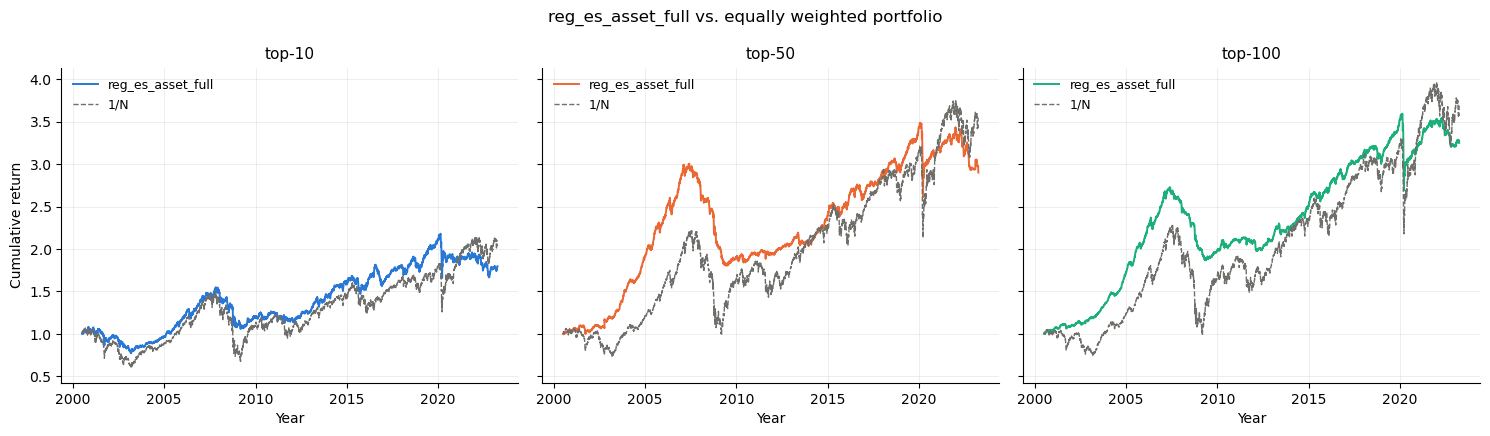

In [6]:
# One panel per universe size: strategy vs. the 1/N portfolio on the same universe.
fig, axes = plt.subplots(1, len(sizes), figsize=(5 * len(sizes), 4.4), sharey=True)
axes = [axes] if len(sizes) == 1 else list(axes)

for ax, size in zip(axes, sizes):
    curve = cumulative(runs[size]["returns"])
    ax.plot(curve.index, curve.values, color=color_of[size], linewidth=1.4, label=strategy_short)
    if size in ref_runs:
        ref = cumulative(ref_runs[size]["returns"])
        ax.plot(ref.index, ref.values, color=REF_COLOR, linewidth=1.0, linestyle="--", label="1/N")
    style_axis(ax, f"top-{size}", ylabel="Cumulative return" if ax is axes[0] else "")
    ax.legend(frameon=False, loc="upper left", fontsize=9)

fig.suptitle(f"{STRATEGY} vs. equally weighted portfolio", fontsize=12)
fig.tight_layout()
save(fig, f"{STRATEGY}_cumulative_panels")
plt.show()